# LLL-SP: full LLL vs. greedy lower bound vs. dyadic

Compare **Lovász** and **Siegel** stochastic LLL-SP on one shared initial **NTRU-shaped circulant q-ary proxy** with prescribed even dimension `n` and integer modulus `q`. This is the fast `[qI,0]; [H,I]` GSO proxy, **not** an actual Gaussian `f,g` NTRU instance.

Six independent simulator objects all start from exactly the same initial GSO and μ-matrix. The greedy and dyadic schedulers use the existing windowed simulator and external-μ resampling. The full-LLL baseline uses one unrestricted `run()` call. Budget-limited reductions are **not** necessarily fully reduced; compare quality as well as swaps.

## 1. Configuration

In [21]:
from math import ceil

# The notebook must be run from the directory containing the compiled
# sandpile_mpfr extension, lllsp_schedulers.py and block_lllsp_estimator.py.
n = 1024*2                       # Even ambient dimension
q = ceil(2**166.01)             # Explicit integer modulus; change freely
seed = 14

condition_params = dict(delta=0.95, eta=0.51)
fptype = "mpfr"             # "double" or "mpfr" ("dd" is not implemented)
precision = 128               # Used ONLY for fptype="mpfr"

# Experiment budgets and scheduling parameters
beta = 144 #max(2, n // 4)         # Greedy window width
greedy_max_blocks = 0x8000      # Safety cap; lower-bound criterion may stop first
dyadic_max_tours = 0x8000          # A dyadic tour consists of a central reduction followed by the left and the right ones 
# (TBD: splitting it into odd-even tours will make this scheduler parralizeable)
max_swaps_per_call = 0x400000000
resample_external = True      # Post-block μ resampling, not part of sim.run()
record_blocks = False         # Set True to inspect per-window swap statistics

assert n >= 2 and n % 2 == 0
assert isinstance(q, int) and q >= 2
assert fptype in ("double", "mpfr")


## 2. Generate one reproducible circulant NTRU-like state

In [22]:
import random
from time import perf_counter
from mpmath import mp
from sandpile_mpfr import SandpileSeq
from lllsp_schedulers import GreedyScheduler, DyadicScheduler
from block_lllsp_estimator import run_block_estimator
import math
import pandas as pd
import matplotlib.pyplot as plt

def initial_ntru_proxy(n, q, seed, precision):
    """Return (squared GS lengths, full μ) for [qI,0];[H,I].

    H is a random centered integer circulant; no actual NTRU (f,g) is sampled.
    The initial GSO has n/2 copies of q², followed by n/2 copies of 1.
    """
    d = n // 2
    rng = random.Random(seed)
    h = [rng.randrange(q) for _ in range(d)]
    h = [z if 2*z <= q else z-q for z in h]
    digits = max(25, int(precision * 0.30103) + 12)
    with mp.workprec(max(128, precision + 48)):
        ratios = [mp.nstr(mp.mpf(z)/q, n=digits) for z in h]
    mu = [["0"] * n for _ in range(n)]
    for i in range(d):
        for j in range(d):
            mu[d+i][j] = ratios[(j-i) % d]
    return [str(q*q)] * d + ["1"] * d, mu

# Keep source arrays unchanged; SandpileSeq copies these into its own storage.
t0 = perf_counter()
initial_state = initial_ntru_proxy(n, q, seed, precision)
print(f"Initial-state preparation: {perf_counter() - t0:.3f} s")

def new_sim(condition):
    return SandpileSeq(
        initial_state,
        condition=condition,
        fptype=fptype,
        precision=precision,  # ignored for double by design
        seed=seed,
        trace_swaps=False,
        **condition_params,
    )

def gs_log2(sim):
    r = sim.profile()         # SQUARED GSO lengths
    if sim.fptype == "double":
        return [math.log2(float(v)) / 2 for v in r]
    with mp.workprec(max(128, precision + 32)):
        return [float(mp.log(mp.mpf(v), 2) / 2) for v in r]

def initial_gs_log2():
    with mp.workprec(max(128, precision + 32)):
        return [float(mp.log(mp.mpf(v), 2) / 2) for v in initial_state[0]]


Initial-state preparation: 0.048 s


## 3. Run the six comparisons

Each run uses its own fresh simulator with identical initial data and seed. Schedulers count only stochastic **swaps**, not rejected swap tests. External-μ sampling is enabled only after windowed reductions.

In [23]:
def experiment(condition, strategy):
    sim = new_sim(condition)
    t0 = perf_counter()
    if strategy == "Full LLL":
        try:
            sim.run(max_swaps=max_swaps_per_call)
            reason = "completed"
        except RuntimeError as exc:
            if "max_swaps" not in str(exc):
                raise
            reason = "swap_limit"
        swaps = int(sim.swaps)
        tours = 1
        blocks = 1
    else:
        if strategy == "Greedy lower":
            scheduler = GreedyScheduler(
                n, beta, metric=0,
                delta=condition_params["delta"],
                eta=condition_params["eta"],
                max_blocks=greedy_max_blocks,
            )
        elif strategy == "Dyadic":
            scheduler = DyadicScheduler(n, max_tours=dyadic_max_tours)
        else:
            raise ValueError(strategy)
        result = run_block_estimator(
            sim, scheduler,
            max_swaps_per_block=max_swaps_per_call,
            resample_external=resample_external,
            record_blocks=record_blocks,
        )
        reason = result.reason
        swaps = result.swaps
        tours = result.tours
        blocks = result.block_reductions
    wall_seconds = perf_counter() - t0
    return {
        "condition": condition, "strategy": strategy,
        "swaps": swaps, "wall_s": wall_seconds,
        "tours": tours, "blocks": blocks, "reason": reason,
        "profile": gs_log2(sim),
    }

results = {}
for condition in ("lovasz", "siegel"):
    for strategy in ("Full LLL", "Greedy lower", "Dyadic"):
        row = experiment(condition, strategy)
        results[(condition, strategy)] = row
        print(f"{condition:6s} {strategy:13s}: "
              f"{row['swaps']:>12,} swaps, "
              f"{row['wall_s']:>9.3f} s, "
              f"{row['blocks']:>5} blocks, {row['reason']}")


lovasz Full LLL     :  201,005,851 swaps,    83.073 s,     1 blocks, completed
lovasz Greedy lower :   19,778,504 swaps,    11.394 s,    36 blocks, scheduler_stop
lovasz Dyadic       :  202,638,044 swaps,    84.612 s,    31 blocks, scheduler_stop
siegel Full LLL     :   33,578,940 swaps,    11.122 s,     1 blocks, completed
siegel Greedy lower :    7,975,549 swaps,     6.179 s,    37 blocks, scheduler_stop
siegel Dyadic       :   33,059,677 swaps,    11.742 s,    31 blocks, scheduler_stop


## 4. Plot all six final profiles

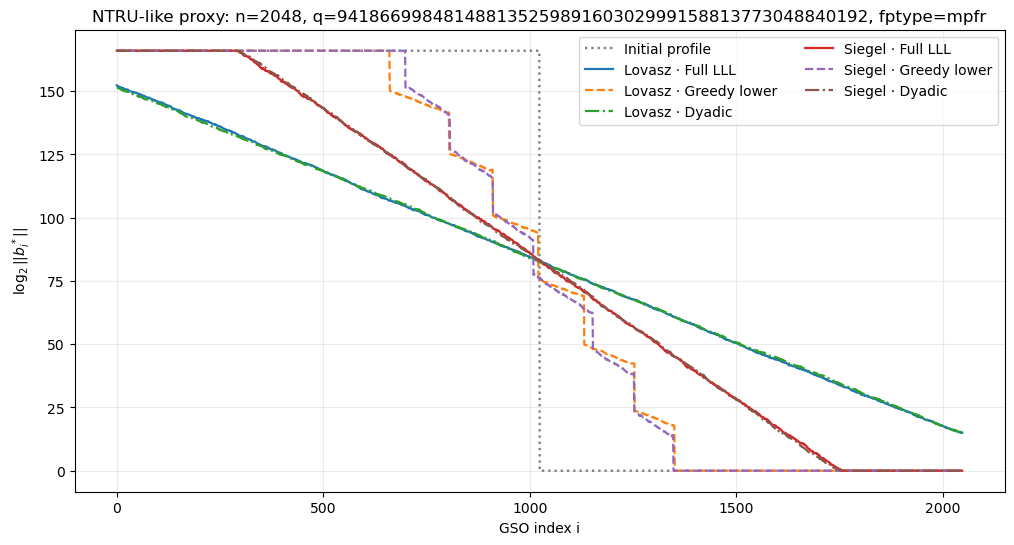

In [24]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(range(n), initial_gs_log2(), color="0.5", linestyle=":",
        linewidth=1.7, label="Initial profile")
styles = {"Full LLL": "-", "Greedy lower": "--", "Dyadic": "-."}
for (condition, strategy), row in results.items():
    ax.plot(range(n), row["profile"], linestyle=styles[strategy],
            linewidth=1.6, label=f"{condition.title()} · {strategy}")
ax.set(xlabel="GSO index i", ylabel=r"$\log_2 ||b_i^*||$",
       title=f"NTRU-like proxy: n={n}, q={q}, fptype={fptype}" )
ax.grid(alpha=0.25)
ax.legend(ncol=2)
plt.show()


## 5. Swap counts, runtimes and quality

The swap ratio uses **full LLL under the same condition** as baseline. Differences in the stopping criteria mean that a lower swap count does *not* automatically indicate a better scheduler. We also report final global log-potential and its change from the common initial profile.

,condition,strategy,swaps,relative_swaps,wall_s,blocks,tours,potential_drop,reason
0,lovasz,Full LLL,201005851,1.000000,83.072695,1,1,2.676200e+07,completed
1,lovasz,Greedy lower,19778504,0.098398,11.393649,36,36,2.729959e+06,scheduler_stop
2,lovasz,Dyadic,202638044,1.008120,84.611686,31,11,2.706286e+07,scheduler_stop
3,siegel,Full LLL,33578940,1.000000,11.121997,1,1,1.009206e+07,completed
4,siegel,Greedy lower,7975549,0.237516,6.178895,37,37,2.450280e+06,scheduler_stop
5,siegel,Dyadic,33059677,0.984536,11.742345,31,11,9.976310e+06,scheduler_stop


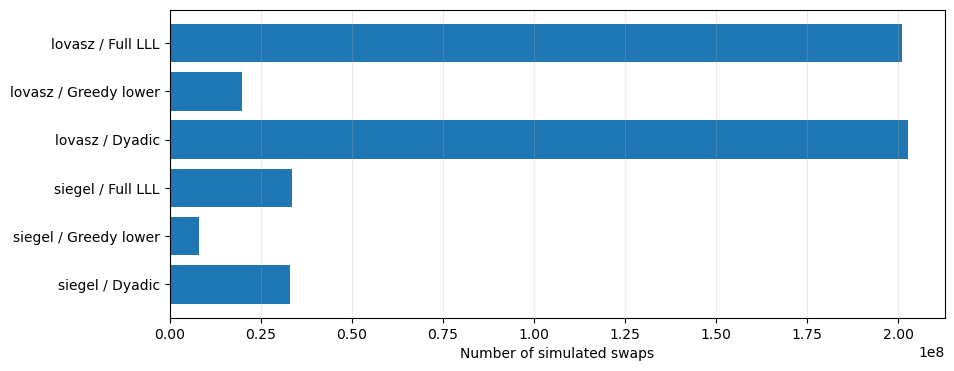

In [25]:
def potential(x):
    return math.fsum((len(x)-i)*v for i, v in enumerate(x))

init_potential = potential([v * math.log(2) for v in initial_gs_log2()])
rows = []
for (condition, strategy), row in results.items():
    full = results[(condition, "Full LLL")]["swaps"]
    p_final = potential([v * math.log(2) for v in row["profile"]])
    rows.append({
        "condition": condition, "strategy": strategy,
        "swaps": row["swaps"],
        "relative_swaps": row["swaps"] / full if full else float("nan"),
        "wall_s": row["wall_s"],
        "blocks": row["blocks"], "tours": row["tours"],
        "potential_drop": init_potential - p_final,
        "reason": row["reason"],
    })
report = pd.DataFrame(rows)
display(report)

fig, ax = plt.subplots(figsize=(10, 4))
labels = [f"{r['condition']} / {r['strategy']}" for r in rows]
ax.barh(labels, [r["swaps"] for r in rows])
ax.set_xlabel("Number of simulated swaps")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.25)
plt.show()


### Interpretation reminders

- A single dyadic tour includes a full-width final block with this scheduler, whereas the greedy lower-bound condition can stop without achieving full LLL reducedness.
- The `precision` parameter applies only to MPFR; using `fptype="double"` gives native binary64 arithmetic. For large `q`, double may overflow/underflow.
- The six runs are reproducible from a shared initial state, but the paths consume different numbers of random draws. Their stochastic trajectories are **not coupled**.
- In particular, using `resample_external=True` changes μ outside the reduced window only **after** each block, following our separate approximation.
- `reason="scheduler_stop"` on dyadic typically means its tour budget was reached, not necessarily that all global conditions have been checked after the last block.
